# Image Checks — CUB-200-2011 Photos (R2, for R4)

`dataPrep.ipynb` prepares the **tabular** dataset. This notebook is the first step for the **image** dataset that the
neural networks (R4) will use: it checks every photo, finds problems, and writes one tidy table that the rest of the
image pipeline reads.

| Image pipeline step | What it does |
|---|---|
| 1. `imagePrep.ipynb` (this notebook) | checks every photo, clips the bounding boxes, writes `data/cub_images.csv` |
| 2. `python scripts/prepare_images.py` | converts to RGB, crops to the box + 10% margin, resizes (shorter side 256 px) |
| 3. [`05_image_preparation.ipynb`](05_image_preparation.ipynb) | checks the cropped images, the train/validation/test split, and shows augmentation |
| 4. `scripts/augmentation.py` | `make_loaders()`: PyTorch loaders for R4, augmentation on training images only |

**Input:** `CUB_200_2011/images/`, `images.txt`, `image_class_labels.txt`, `train_test_split.txt`, `bounding_boxes.txt`.
**Output:** `data/cub_images.csv` (git-ignored, re-run this notebook to recreate it) and figures in
`documentation/figures/` (prefix `images_`).

Every row has the same `image_id`, `class_id` and official split as the tabular files, so tabular and image models are
trained and tested on exactly the same photos.

| Step | Section |
|---|---|
| Build the image table | 2 |
| Check every photo (missing, unreadable, colour mode, size) | 3 |
| Check the bounding boxes | 4 |
| How much of the photo is the bird? | 5 |
| Save + recommendations for R4 | 6 |

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
SPLIT = 'is_train'  # official split, same as the main model notebooks
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
FIGURES = ROOT / 'documentation' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
META_COLS = ['image_id', 'class_id', 'class_name', 'is_train']  # never used as features

# One consistent look for every figure
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'font.size': 9, 'legend.frameon': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'

def load_features(variant='A'):
    """Feature table written by dataPrep.ipynb (variant A = raw 0/1 attributes)."""
    path = DATA / f'cub_features_{variant}.csv'
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run notebooks/dataPrep.ipynb first')
    df = pd.read_csv(path).copy()   # .copy() keeps the 300+ columns in one memory block
    df['species'] = df.class_name.str.split('.', n=1).str[1].str.replace('_', ' ')
    return df.copy()

def save_figure(fig, name):
    fig.savefig(FIGURES / f'{name}.png')

# Dataset folder, found the same way as in dataPrep.ipynb: inside data/raw/, or CUB_200_2011/ at the repo root
CUB = next((p.parent for p in (ROOT / 'data' / 'raw').rglob('image_class_labels.txt')), ROOT / 'CUB_200_2011')
assert CUB.exists(), 'Dataset not found - see README "Getting the data"'

from PIL import Image
import matplotlib.patches as patches

def read_ws(path, names):
    return pd.read_csv(path, sep=r'\s+', header=None, names=names)

## 2. Build the image table

One row per photo: its file path, species, official split and bounding box.

In [2]:
table = (read_ws(CUB / 'images.txt', ['image_id', 'image_path'])
         .merge(read_ws(CUB / 'image_class_labels.txt', ['image_id', 'class_id']))
         .merge(read_ws(CUB / 'train_test_split.txt', ['image_id', 'is_train']))
         .merge(read_ws(CUB / 'bounding_boxes.txt', ['image_id', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h'])))
table['species'] = table.image_path.str.split('/').str[0].str.split('.', n=1).str[1].str.replace('_', ' ')

assert len(table) == 11788 and table.image_id.is_unique
print(f'{len(table):,} photos, {table.class_id.nunique()} species, '
      f'{table.is_train.sum():,} train / {(table.is_train == 0).sum():,} test')
table.head(3)

11,788 photos, 200 species, 5,994 train / 5,794 test


,image_id,image_path,class_id,is_train,bbox_x,bbox_y,bbox_w,bbox_h,species
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,60.0,27.0,325.0,304.0,Black footed Albatross
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,139.0,30.0,153.0,264.0,Black footed Albatross
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,14.0,112.0,388.0,186.0,Black footed Albatross


## 3. Check every photo

Each photo is opened once to record its size and colour mode. A CNN needs every input to have **3 colour channels** and
**one fixed size**, so both are worth knowing before training. Only the file header is read, so this takes about a minute.

In [3]:
widths, heights, modes, problems = [], [], [], []
for i, rel_path in enumerate(table.image_path, start=1):
    try:
        with Image.open(CUB / 'images' / rel_path) as img:
            widths.append(img.width); heights.append(img.height); modes.append(img.mode)
    except Exception as e:          # missing or unreadable file
        widths.append(0); heights.append(0); modes.append('ERROR'); problems.append((rel_path, str(e)))
    if i % 2000 == 0 or i == len(table):
        print(f'\r  checked {i:,}/{len(table):,} photos', end='')
print()

table['width'], table['height'], table['mode'] = widths, heights, modes
pd.Series({
    'missing or unreadable photos': len(problems),
    'colour modes': table['mode'].value_counts().to_dict(),
    'width range (px)': f"{table.width.min()}-{table.width.max()}",
    'height range (px)': f"{table.height.min()}-{table.height.max()}",
}, name='result').to_frame()

  checked 2,000/11,788 photos

  checked 4,000/11,788 photos

  checked 6,000/11,788 photos

  checked 8,000/11,788 photos

  checked 10,000/11,788 photos

  checked 11,788/11,788 photos


,result
missing or unreadable photos,0
colour modes,"{'RGB': 11780, 'L': 8}"
width range (px),121-500
height range (px),120-500


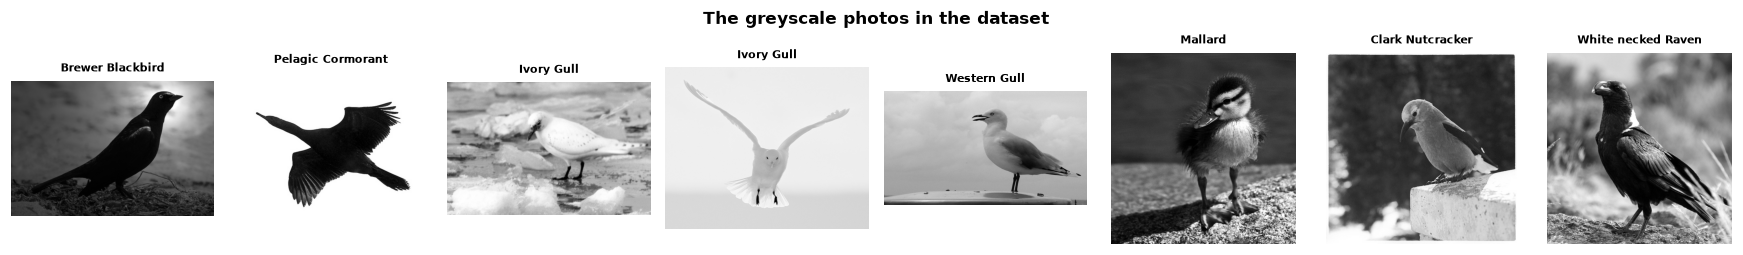

In [4]:
grey = table[table['mode'] != 'RGB']
fig, axes = plt.subplots(1, len(grey), figsize=(2.0 * len(grey), 2.3))
for ax, (_, row) in zip(np.atleast_1d(axes), grey.iterrows()):
    ax.imshow(Image.open(CUB / 'images' / row.image_path), cmap='gray')
    ax.set_title(row.species, fontsize=7)
    ax.axis('off')
fig.suptitle('The greyscale photos in the dataset', fontweight='bold')
plt.tight_layout()
save_figure(fig, 'images_greyscale')
plt.show()

**Finding:** no photo is missing or unreadable, but **8 photos are greyscale** (1 channel instead of 3) and sizes vary.

**Decision:** keep all photos. In R4, convert every photo with `.convert('RGB')` (a greyscale photo becomes 3 identical
channels) and resize to one fixed input size. The exact size is an R4 modelling choice.

## 4. Check the bounding boxes

Cropping to the box lets a CNN look at the bird instead of the background, but a box must lie inside its photo.

In [5]:
inside = ((table.bbox_x >= 0) & (table.bbox_y >= 0) &
          (table.bbox_x + table.bbox_w <= table.width + 1) &       # 1 px tolerance for rounding
          (table.bbox_y + table.bbox_h <= table.height + 1))
table['bbox_clipped'] = (~inside).astype(int)
print(f'Boxes that extend past the photo border: {int(table.bbox_clipped.sum())}')
table.loc[~inside, ['image_id', 'width', 'height', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']]

Boxes that extend past the photo border: 8


,image_id,width,height,bbox_x,bbox_y,bbox_w,bbox_h
959,960,177,131,27.0,6.0,148.0,127.0
998,999,500,375,2.0,69.0,457.0,311.0
1217,1218,500,410,92.0,51.0,440.0,303.0
3411,3412,500,375,204.0,120.0,295.0,257.0
5006,5007,500,333,34.0,33.0,438.0,326.0
6155,6156,500,334,16.0,69.0,366.0,267.0
6272,6273,500,333,3.0,31.0,387.0,304.0
9761,9762,194,146,35.0,16.0,162.0,101.0


In [6]:
# Clip every box to the photo border, so a crop never asks for pixels outside the image
table['bbox_x'] = table.bbox_x.clip(lower=0)
table['bbox_y'] = table.bbox_y.clip(lower=0)
table['bbox_w'] = np.minimum(table.bbox_w, table.width - table.bbox_x)
table['bbox_h'] = np.minimum(table.bbox_h, table.height - table.bbox_y)
assert ((table.bbox_x + table.bbox_w <= table.width) & (table.bbox_y + table.bbox_h <= table.height)).all()

**Finding and decision:** 8 boxes stick out past the edge by up to about 30 px (an annotation slip). They are **clipped**
to the photo border and flagged in `bbox_clipped`. The original files are not changed.

## 5. How much of the photo is the bird?

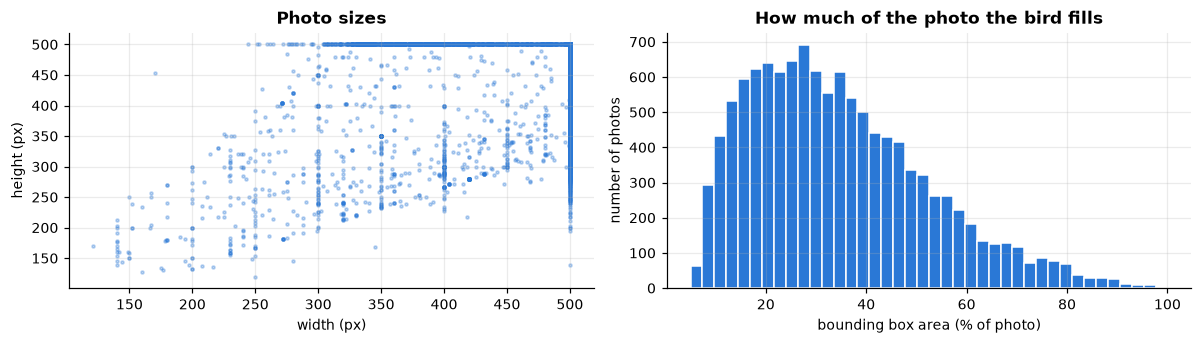

Median share of the photo covered by the bird: 32%


In [7]:
table['bbox_area_share'] = (table.bbox_w * table.bbox_h) / (table.width * table.height)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].scatter(table.width, table.height, s=4, alpha=0.3, color=BLUE)
axes[0].set(title='Photo sizes', xlabel='width (px)', ylabel='height (px)')
axes[1].hist(table.bbox_area_share * 100, bins=40, color=BLUE, edgecolor='white')
axes[1].set(title='How much of the photo the bird fills', xlabel='bounding box area (% of photo)', ylabel='number of photos')
plt.tight_layout()
save_figure(fig, 'images_sizes')
plt.show()
print(f'Median share of the photo covered by the bird: {table.bbox_area_share.median():.0%}')

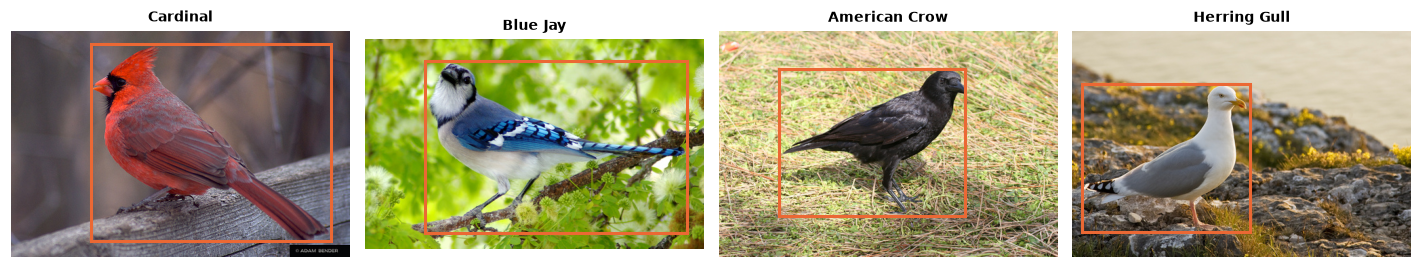

In [8]:
# Example photos with their (clipped) bounding boxes
show = ['Cardinal_0085_19162', 'Blue_Jay_0015_62916', 'American_Crow_0117_25090', 'Herring_Gull_0105_46113']
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, file_stem in zip(axes, show):
    row = table[table.image_path.str.contains(file_stem, regex=False)].iloc[0]
    ax.imshow(Image.open(CUB / 'images' / row.image_path).convert('RGB'))
    ax.add_patch(patches.Rectangle((row.bbox_x, row.bbox_y), row.bbox_w, row.bbox_h,
                                   fill=False, edgecolor=ORANGE, linewidth=2))
    ax.set_title(row.species, fontsize=9)
    ax.axis('off')
plt.tight_layout()
save_figure(fig, 'images_boxes')
plt.show()

**Finding:** photos are mostly 500 px on the long side, and the bird typically covers only about a third of the photo.
Cropping to the box removes most of the background, which otherwise competes with the bird for the CNN's attention.

## 6. Save + recommendations for R4

In [9]:
columns = ['image_id', 'image_path', 'class_id', 'species', 'is_train', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h',
           'bbox_clipped', 'width', 'height', 'mode']
out = DATA / 'cub_images.csv'
table[columns].to_csv(out, index=False)
print(f'Saved {out.relative_to(ROOT)}: {table.shape[0]:,} rows')

# Next step: python scripts/prepare_images.py (crop + resize every photo using this table)

Saved data\cub_images.csv: 11,788 rows


| Issue | Finding | Where it is handled |
|---|---|---|
| Colour mode | 8 greyscale photos | `prepare_images.py` converts every photo to RGB |
| Size | widths and heights vary (mostly 500 px on the long side) | `prepare_images.py` resizes (shorter side 256 px) |
| Background | the bird fills about a third of the photo | `prepare_images.py` crops to the box + 10% margin |
| Boxes | 8 extend past the border | clipped here, in `cub_images.csv` |
| Split | same official split as the tabular files | `augmentation.py` keeps the test set untouched and takes validation from the training set |
| Few photos per class | 29–30 training photos per species | `augmentation.py` augments training photos only (flips, crops, small rotations) |